# Tópico 13 - Transformada-Z

## Visão Geral e Objetivos
Neste notebook, investigamos a **Transformada-Z** e sua aplicação na representação e análise de sinais e sistemas discretos no plano complexo $z$. Os principais objetivos são:
1. **Conceituação da Variável Complexa $z$**: Compreender a representação polar $z = r e^{j\omega}$, em que $r = |z|$ define o raio (magnitude/raio de atenuação ou crescimento) e $\omega = \angle z$ representa a frequência angular discreta (rad/amostra).
2. **Transformadas de Sequências Elementares**: Avaliar analítica e numericamente as transformadas-Z de sequências fundamentais como o impulso unitário $\delta[n]$, o degrau unitário $u[n]$ e a exponencial discreta $x[n] = a^n u[n]$.
3. **Mapeamento no Plano-$z$ e Polos/Zeros**: Identificar a posição das raízes no plano complexo $z$ e sua relação com o círculo unitário ($|z| = 1$).
4. **Gerenciamento de Figuras**: Exportar os gráficos gerados diretamente para o diretório local de simulação.

In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal

# Garantir a criação do diretório local para exportação das imagens
os.makedirs(".", exist_ok=True)

## 1. Expressões Analíticas e Simulação de Sequências Discretas Elementares

A Transformada-Z bilateral de uma sequência de tempo discreto $x[n]$ é definida por:
$$X(z) = \mathcal{Z}\{x[n]\} = \sum_{n=-\infty}^{+\infty} x[n] z^{-n}, \quad z = r e^{j\omega}$$

Abaixo, apresentamos três sequências causais elementares:
1. **Impulso Unitário**:
   $$x_1[n] = \delta[n] \stackrel{\mathcal{Z}}{\longleftrightarrow} X_1(z) = 1, \quad \text{ROC: Todo o plano } z$$
2. **Degrau Unitário**:
   $$x_2[n] = u[n] \stackrel{\mathcal{Z}}{\longleftrightarrow} X_2(z) = \frac{1}{1 - z^{-1}} = \frac{z}{z - 1}, \quad \text{ROC: } |z| > 1$$
3. **Sequência Exponencial Real Causal**:
   $$x_3[n] = a^n u[n] \stackrel{\mathcal{Z}}{\longleftrightarrow} X_3(z) = \frac{1}{1 - a z^{-1}} = \frac{z}{z - a}, \quad \text{ROC: } |z| > |a|$$

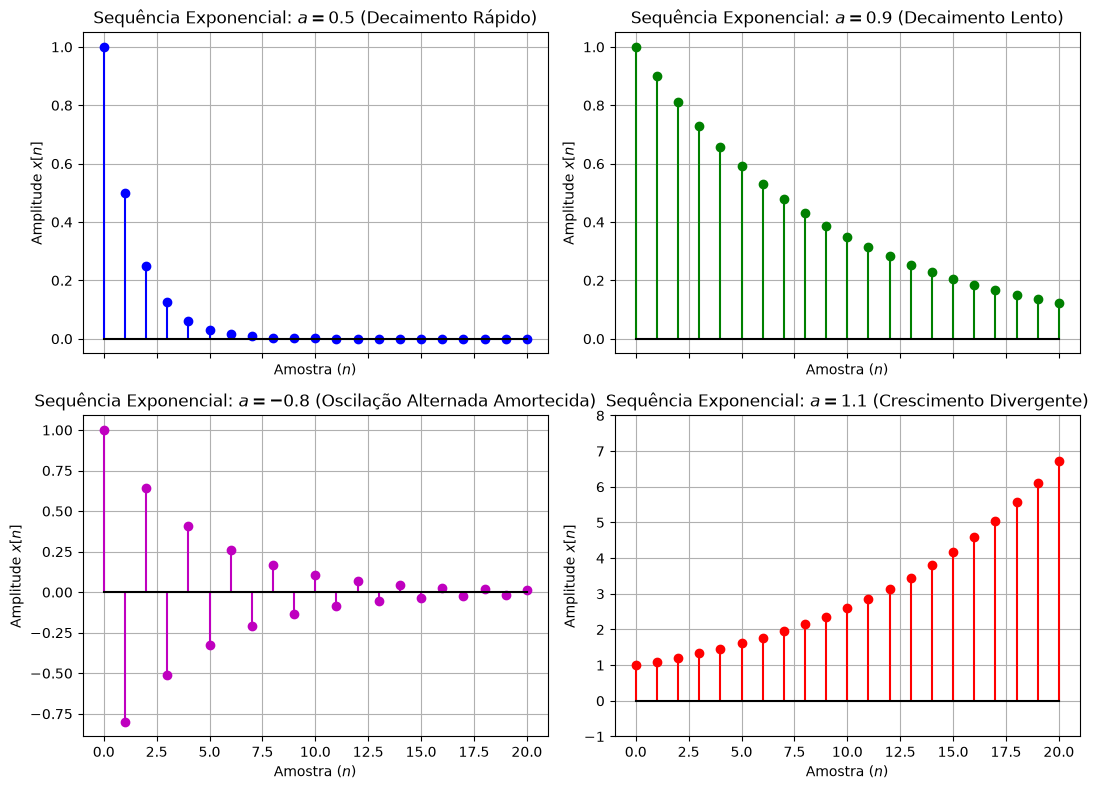

In [2]:
# Vetor discreto n de 0 a 20 amostras
n = np.arange(0, 21)

# Parâmetros de base a para a exponencial a^n u[n]
valores_a = [0.5, 0.9, -0.8, 1.1]
titulos_a = [
    r'$a = 0.5$ (Decaimento Rápido)',
    r'$a = 0.9$ (Decaimento Lento)',
    r'$a = -0.8$ (Oscilação Alternada Amortecida)',
    r'$a = 1.1$ (Crescimento Divergente)'
]
cores = ['b', 'g', 'm', 'r']

fig1, axs1 = plt.subplots(2, 2, figsize=(11, 8), sharex=True)
axs1 = axs1.flatten()

for idx, a in enumerate(valores_a):
    x_n = (a**n)
    
    axs1[idx].stem(n, x_n, linefmt=f'{cores[idx]}-', markerfmt=f'{cores[idx]}o', basefmt='k-')
    axs1[idx].set_title(f'Sequência Exponencial: {titulos_a[idx]}')
    axs1[idx].set_xlabel('Amostra ($n$)')
    axs1[idx].set_ylabel('Amplitude $x[n]$')
    axs1[idx].grid(True)
    if a == 1.1:
        axs1[idx].set_ylim(-1, 8)

plt.tight_layout()
fig1.savefig("grafico_transformada_z_sequencias.png")
plt.show()

## 2. Polos, Zeros e Mapeamento de Sistemas Discretos no Plano-$z$

Em sistemas discretos descritos por equações de diferenças, a função de transferência $H(z) = \frac{Y(z)}{X(z)}$ é uma razão de polinômios em $z^{-1}$ ou $z$:
$$H(z) = b_0 \frac{\prod_{k=1}^M (1 - z_k z^{-1})}{\prod_{k=1}^N (1 - p_k z^{-1})} = b_0 z^{N-M} \frac{\prod_{k=1}^M (z - z_k)}{\prod_{k=1}^N (z - p_k)}$$

- **Círculo Unitário ($|z| = 1$)**: Atua como a fronteira fundamental do plano-$z$, correspondendo à avaliação da frequência angular discreta $\omega$ de $-\pi$ a $+\pi$ rad/amostra.
- **Polos Internos ($|p_k| < 1$)**: Produzem respostas transientes causais amortecidas no tempo ($p_k^n \rightarrow 0$).
- **Polos Externos ($|p_k| > 1$)**: Produzem respostas transientes causais divergentes no tempo ($p_k^n \rightarrow \infty$).

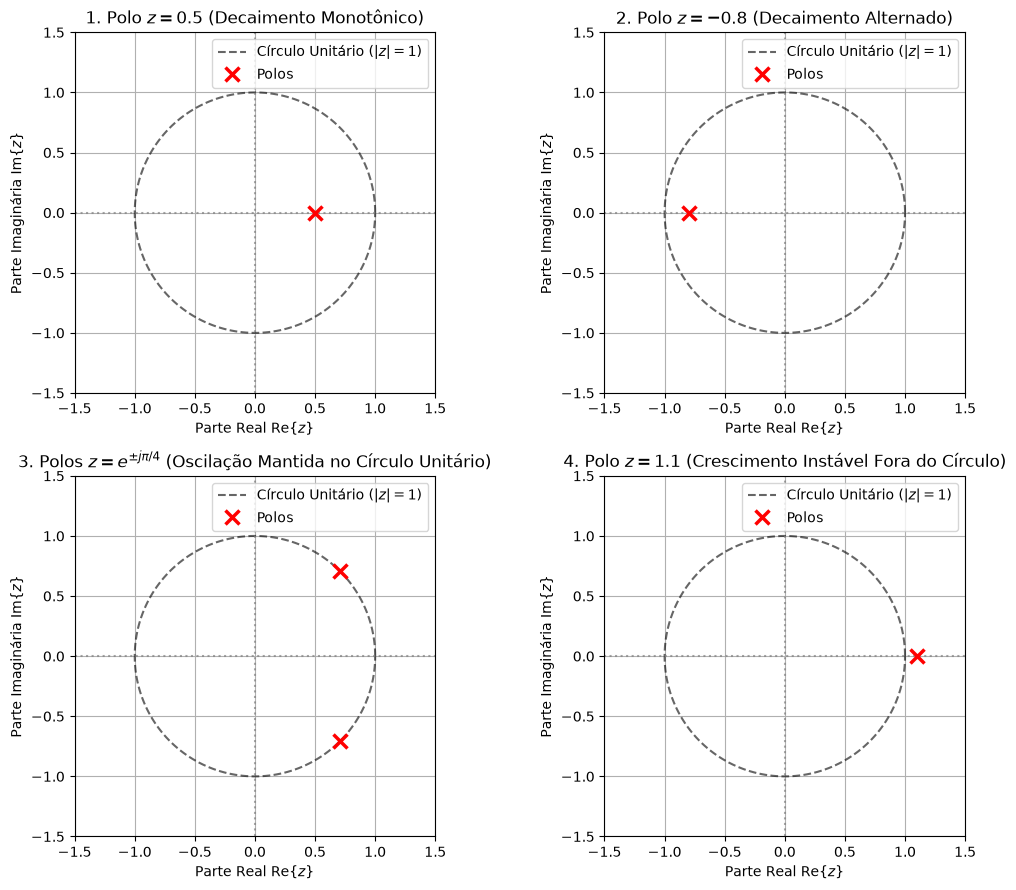

In [3]:
# Definição de 4 sistemas discretos causais com diferentes posições de polos no plano-z
# Sistema 1: Polo real em z = 0.5
sys1 = signal.dlti([1.0], [1.0, -0.5])

# Sistema 2: Polo real negativo em z = -0.8
sys2 = signal.dlti([1.0], [1.0, 0.8])

# Sistema 3: Polos complexos conjugados sobre o círculo unitário (r = 1.0, omega = pi/4)
w3 = np.pi / 4
sys3 = signal.dlti([1.0], [1.0, -2 * np.cos(w3), 1.0])

# Sistema 4: Polo externo instável em z = 1.1
sys4 = signal.dlti([1.0], [1.0, -1.1])

sistemas_z = [sys1, sys2, sys3, sys4]
titulos_z = [
    r'1. Polo $z = 0.5$ (Decaimento Monotônico)',
    r'2. Polo $z = -0.8$ (Decaimento Alternado)',
    r'3. Polos $z = e^{\pm j\pi/4}$ (Oscilação Mantida no Círculo Unitário)',
    r'4. Polo $z = 1.1$ (Crescimento Instável Fora do Círculo)'
]

fig2, axs2 = plt.subplots(2, 2, figsize=(11, 9))
axs2 = axs2.flatten()

# Função para desenhar o mapa de polos e zeros com o círculo unitário
for idx, sys in enumerate(sistemas_z):
    polos = sys.poles
    zeros = sys.zeros
    
    # Desenho do Círculo Unitário (|z| = 1)
    theta = np.linspace(0, 2 * np.pi, 200)
    axs2[idx].plot(np.cos(theta), np.sin(theta), 'k--', alpha=0.6, label='Círculo Unitário ($|z|=1$)')
    
    # Eixos Real e Imaginário
    axs2[idx].axhline(0, color='gray', linestyle=':', alpha=0.7)
    axs2[idx].axvline(0, color='gray', linestyle=':', alpha=0.7)
    
    # Plotar Polos (X) e Zeros (O)
    if len(polos) > 0:
        axs2[idx].plot(np.real(polos), np.imag(polos), 'rx', markersize=10, markeredgewidth=2.5, label='Polos')
    if len(zeros) > 0:
        axs2[idx].plot(np.real(zeros), np.imag(zeros), 'bo', markersize=8, markerfacecolor='none', markeredgewidth=2, label='Zeros')
        
    axs2[idx].set_title(titulos_z[idx])
    axs2[idx].set_xlabel(r'Parte Real $\text{Re}\{z\}$')
    axs2[idx].set_ylabel(r'Parte Imaginária $\text{Im}\{z\}$')
    axs2[idx].set_xlim(-1.5, 1.5)
    axs2[idx].set_ylim(-1.5, 1.5)
    axs2[idx].set_aspect('equal')
    axs2[idx].grid(True)
    axs2[idx].legend(loc='upper right')

plt.tight_layout()
fig2.savefig("grafico_transformada_z_plano_z.png")
plt.show()

## 3. Síntese dos Resultados sobre a Transformada-Z
- **Representação no Plano Complexo $z$**: A variável $z = r e^{j\omega}$ mapeia simultaneamente a taxa de amortecimento/crescimento discreto ($r = |z|$) e a frequência de oscilação por amostra ($\omega = \angle z$).
- **Fronteira de Estabilidade**: O círculo unitário ($|z| = 1$) no plano-$z$ desempenha o papel análogo ao eixo imaginário $j\omega$ no plano-$s$. Polos causais estritamente internos ao círculo unitário ($|p_k| < 1$) garantem a convergência assintótica do sinal discreto.
- **Modos de Oscilação**: Polos reais positivos geram respostas amortecidas puramente monotônicas; polos reais negativos induzem oscilação sinal-alternada a cada amostra ($(-1)^n$); polos complexos conjugados introduzem oscilação senoidal discreta na frequência $\omega_0 = \arg(p_k)$.